In [456]:
import pandas as pd
import os
import numpy as np
from scipy.signal import butter, filtfilt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from colorspacious import cspace_convert
import colorsys
import cv2 as cv

In [315]:
path=r'E:\DLR\0311'
data2=pd.read_csv(path+'\\'+'data2sec.csv')

In [317]:
def datapreparet(datain):
    dataa=np.array(datain[datain.columns[1:13]])
    labela=np.array(datain[datain.columns[-1]])
    indn1=np.where(dataa[:,2]>0.5)[0]
    dataa1=dataa[indn1,:]
    labela1=labela[indn1]
    indn2=np.where(dataa1[:,6]>0.5)[0]
    dataa2=dataa1[indn2,:]
    labela2=labela1[indn2]
    indn3=np.where(dataa2[:,10]>0.5)[0]
    dataa3=dataa2[indn3,:]
    labela3=labela2[indn3]
    indn4=np.where(dataa3[:,1]<3500)[0]
    dataa4=dataa3[indn4,:]
    labela4=labela3[indn4]
    indn5=np.where(dataa4[:,5]<3500)[0]
    dataa5=dataa4[indn5,:]
    labela5=labela4[indn5]
    indn6=np.where(dataa5[:,9]<3500)[0]
    dataa6=dataa5[indn6,:]
    labela6=labela5[indn6]
    indn7=np.where(labela6!=12833)[0]
    dataa7=dataa6[indn7,:]
    labela7=labela6[indn7]
    indn8=np.where(labela7!=9507)[0]
    dataa8=dataa7[indn8,:]
    labela8=labela7[indn8]
    labelin=labela8
    datain=dataa8
    
    
 
    all_feature=datain
    all_label=labelin
    return all_feature, all_label

In [318]:
all_feature2, all_label22=datapreparet(data2)
all_label2=np.c_[all_label22,all_label22]

In [319]:
def datasepr(featuresin,idin):
    id_group=idin[:,0]//1000
    ind6=np.where(id_group==6)[0]
    features6out=featuresin[ind6]
    id6out=idin[ind6]
    
    ind9=np.where(id_group==9)[0]
    features9out=featuresin[ind9]
    id9out=idin[ind9]
    
    ind12=np.where(id_group==12)[0]
    features12out=featuresin[ind12]
    id12out=idin[ind12]
    
    ind18=np.where(id_group==18)[0]
    features18out=featuresin[ind18]
    id18out=idin[ind18]
    
    return features6out, id6out, features9out, id9out, features12out, id12out, features18out, id18out

In [320]:
f6outr2, id6outr2, f9outr2, id9outr2, f12outr2, id12outr2, f18outr2, id18outr2=datasepr(all_feature2,all_label2)

In [403]:
id6outr2

array([[6439, 6439],
       [6439, 6439],
       [6439, 6439],
       ...,
       [6913, 6913],
       [6913, 6913],
       [6913, 6913]], dtype=int64)

In [321]:
def featuresepr(featurein):
    meanout=np.c_[featurein[:,0],featurein[:,4],featurein[:,8]]
    rmsout=np.c_[featurein[:,1],featurein[:,5],featurein[:,9]]
    stdout=np.c_[featurein[:,2],featurein[:,6],featurein[:,10]]
    fmeanout=np.c_[featurein[:,3],featurein[:,7],featurein[:,11]]
    return meanout, rmsout, stdout, fmeanout

In [322]:
meanoutr62, rmsoutr62, stdoutr62, alloutr62=featuresepr(f6outr2)
meanoutr92, rmsoutr92, stdoutr92, alloutr92=featuresepr(f9outr2)
meanoutr122, rmsoutr122, stdoutr122, alloutr122=featuresepr(f12outr2)
meanoutr182, rmsoutr182, stdoutr182, alloutr182=featuresepr(f18outr2)

In [462]:
meanall=np.r_[meanoutr62,meanoutr92,meanoutr122,meanoutr182]

In [323]:
num6=len(set(tuple(label) for label in id6outr2))
num9=len(set(tuple(label) for label in id9outr2))
num12=len(set(tuple(label) for label in id12outr2))

In [324]:
num18=len(set(tuple(label) for label in id18outr2))

In [463]:
hisall,edge=np.histogramdd(meanall, bins=10,density=True)

In [464]:
his6all,edge6=np.histogramdd(meanoutr62, bins=edge,density=True)

In [465]:
his9all,edge9=np.histogramdd(meanoutr92, bins=edge,density=True)

In [466]:
his12all,edge12=np.histogramdd(meanoutr122, bins=edge,density=True)

In [467]:
his6alld=his6all * np.diff(edge6[0])[0] * np.diff(edge6[1])[0] * np.diff(edge6[2])[0]

In [468]:
his9alld=his9all * np.diff(edge9[0])[0] * np.diff(edge9[1])[0] * np.diff(edge9[2])[0]

In [469]:
his12alld=his12all * np.diff(edge12[0])[0] * np.diff(edge12[1])[0] * np.diff(edge12[2])[0]

In [470]:
np.sum(his6alld)

1.0

In [471]:
edge6[0][10]=edge6[0][10]+0.00001
edge6[0][0]=edge6[0][0]-0.00001

edge6[1][10]=edge6[1][10]+0.00001
edge6[1][0]=edge6[1][0]-0.00001

edge6[2][10]=edge6[2][10]+0.00001
edge6[2][0]=edge6[2][0]-0.00001

In [472]:
edge9[0][10]=edge9[0][10]+0.00001
edge9[0][0]=edge9[0][0]-0.00001

edge9[1][10]=edge9[1][10]+0.00001
edge9[1][0]=edge9[1][0]-0.00001

edge9[2][10]=edge9[2][10]+0.00001
edge9[2][0]=edge9[2][0]-0.00001

In [473]:
edge12[0][10]=edge12[0][10]+0.00001
edge12[0][0]=edge12[0][0]-0.00001

edge12[1][10]=edge12[1][10]+0.00001
edge12[1][0]=edge12[1][0]-0.00001

edge12[2][10]=edge12[2][10]+0.00001
edge12[2][0]=edge12[2][0]-0.00001

In [476]:
bin_indices6 = [np.digitize(meanoutr62[:, i], bins=edge6[i]) for i in range(3)]
bin_indices9 = [np.digitize(meanoutr92[:, i], bins=edge9[i]) for i in range(3)]

In [477]:
bin_indices12 = [np.digitize(meanoutr122[:, i], bins=edge12[i]) for i in range(3)]

In [478]:
bin_indices_6m=np.array(bin_indices6)-1
bin_indices_9m=np.array(bin_indices9)-1

In [479]:
bin_indices_12m=np.array(bin_indices12)-1

In [480]:
bin_indices_6m[:][:100]

array([[4, 2, 1, ..., 5, 6, 6],
       [5, 3, 2, ..., 4, 4, 5],
       [0, 2, 4, ..., 1, 0, 0]], dtype=int64)

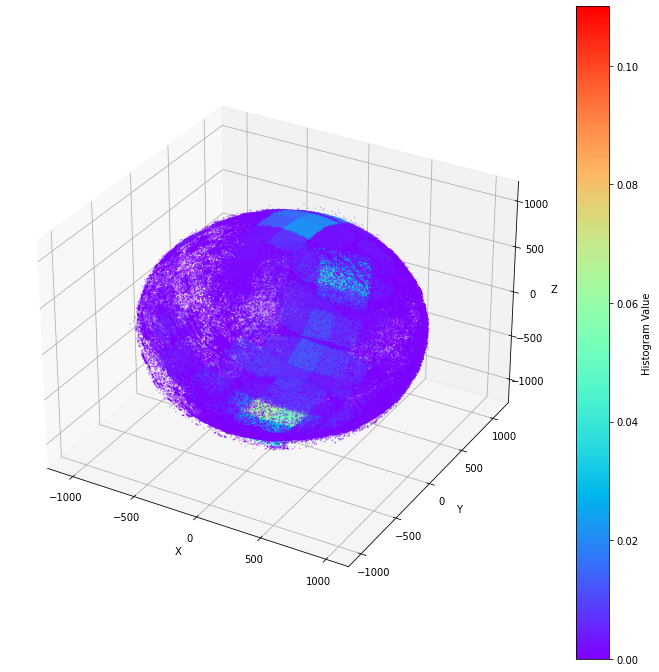

In [491]:
from matplotlib.colors import Normalize
cmap = plt.get_cmap('rainbow')
norm = Normalize(vmin=np.min(his6alld), vmax=np.max(his6alld))

# Create 3D scatter plot
fig=plt.figure(figsize=(12, 12))
ax = fig.add_subplot(111, projection='3d')

# Plot each point with a color representing its histogram value
sc = ax.scatter(meanoutr62[:, 0], meanoutr62[:, 1], meanoutr62[:, 2], c=his6alld[bin_indices_6m[0], bin_indices_6m[1], bin_indices_6m[2]], 
                cmap=cmap,
                vmin=0,vmax=0.11, s=0.1)

# Add color bar
cbar = plt.colorbar(sc)
cbar.set_label('Histogram Value')

# Set labels
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

plt.show()
filesave=r'E:\DLR\motionhist\all'+'\\'+'all6'+'.jpg'
fig.savefig(filesave, bbox_inches='tight', pad_inches=0)

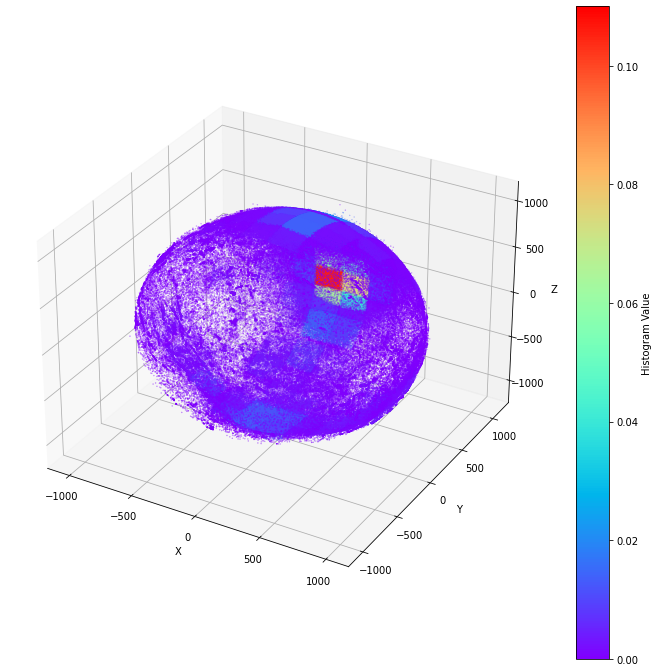

In [487]:
from matplotlib.colors import Normalize
cmap = plt.get_cmap('rainbow')
norm = Normalize(vmin=np.min(his9alld), vmax=np.max(his9alld))

# Create 3D scatter plot
fig=plt.figure(figsize=(12, 12))
ax = fig.add_subplot(111, projection='3d')

# Plot each point with a color representing its histogram value
sc = ax.scatter(meanoutr92[:, 0], meanoutr92[:, 1], meanoutr92[:, 2], c=his9alld[bin_indices_9m[0], bin_indices_9m[1], bin_indices_9m[2]],
                cmap=cmap,
                vmin=0,vmax=0.11, s=0.1)

# Add color bar
cbar = plt.colorbar(sc)
cbar.set_label('Histogram Value')

# Set labels
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

plt.show()
filesave=r'E:\DLR\motionhist\all'+'\\'+'all9'+'.jpg'
fig.savefig(filesave, bbox_inches='tight', pad_inches=0)

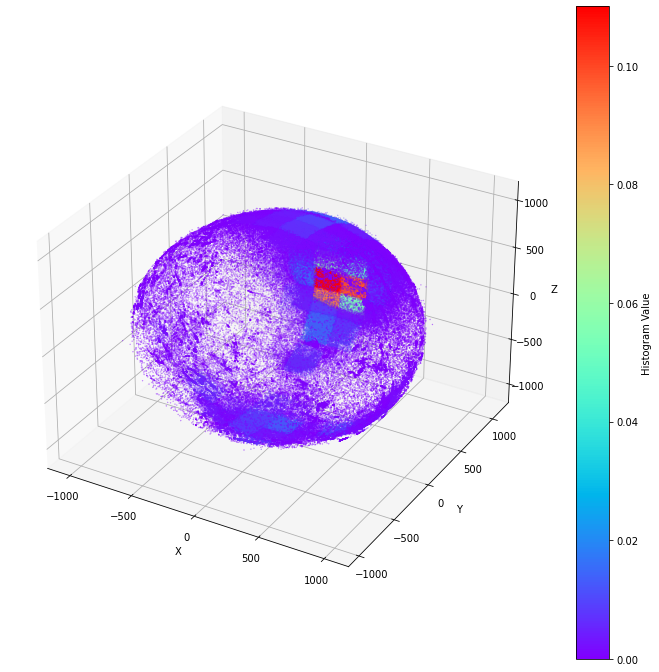

In [486]:
from matplotlib.colors import Normalize
cmap = plt.get_cmap('rainbow')
norm = Normalize(vmin=np.min(his9alld), vmax=np.max(his9alld))

# Create 3D scatter plot
fig=plt.figure(figsize=(12, 12))
ax = fig.add_subplot(111, projection='3d')

# Plot each point with a color representing its histogram value
sc = ax.scatter(meanoutr122[:, 0], meanoutr122[:, 1], meanoutr122[:, 2], c=his12alld[bin_indices_12m[0], bin_indices_12m[1], bin_indices_12m[2]],
                cmap=cmap, 
                vmin=0,vmax=0.11, s=0.1)

# Add color bar
cbar = plt.colorbar(sc)
cbar.set_label('Histogram Value')

# Set labels
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

plt.show()
filesave=r'E:\DLR\motionhist\all'+'\\'+'all12'+'.jpg'
fig.savefig(filesave, bbox_inches='tight', pad_inches=0)

(6439, 6439)


<Figure size 432x288 with 0 Axes>

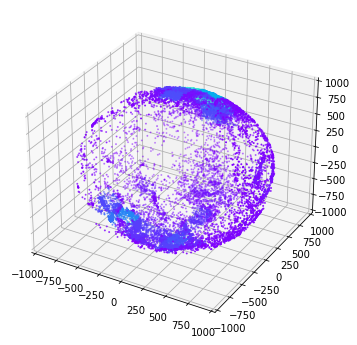

(6457, 6457)


<Figure size 432x288 with 0 Axes>

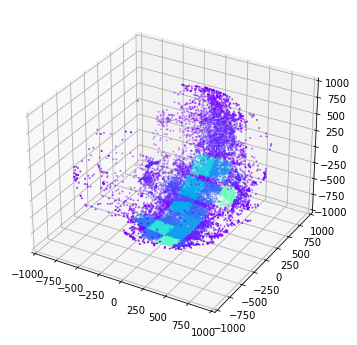

(6507, 6507)


<Figure size 432x288 with 0 Axes>

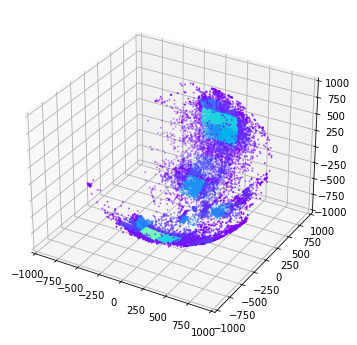

(6617, 6617)


<Figure size 432x288 with 0 Axes>

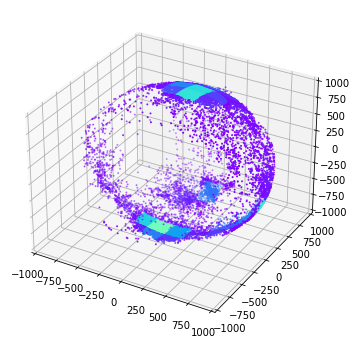

(6658, 6658)


<Figure size 432x288 with 0 Axes>

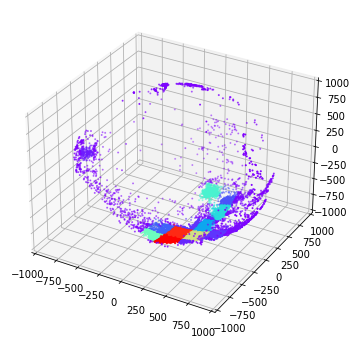

(6660, 6660)


<Figure size 432x288 with 0 Axes>

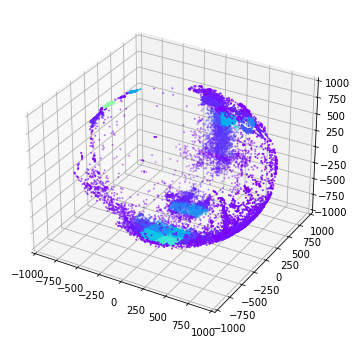

(6746, 6746)


<Figure size 432x288 with 0 Axes>

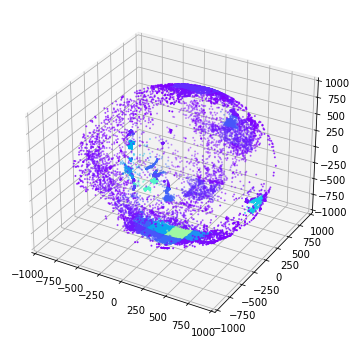

(6753, 6753)


<Figure size 432x288 with 0 Axes>

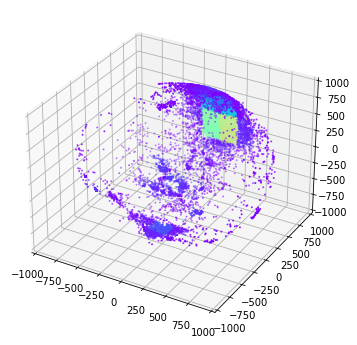

(6754, 6754)


<Figure size 432x288 with 0 Axes>

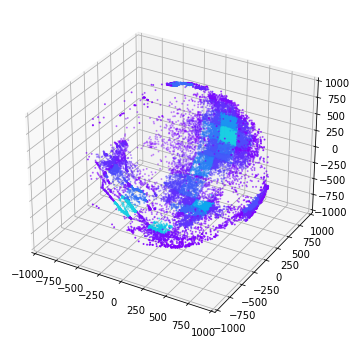

(6762, 6762)


<Figure size 432x288 with 0 Axes>

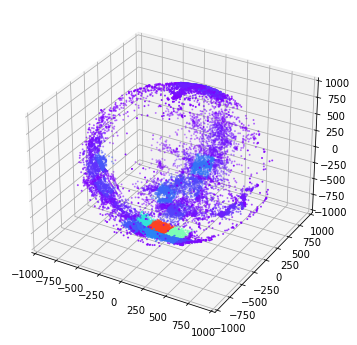

(6768, 6768)


<Figure size 432x288 with 0 Axes>

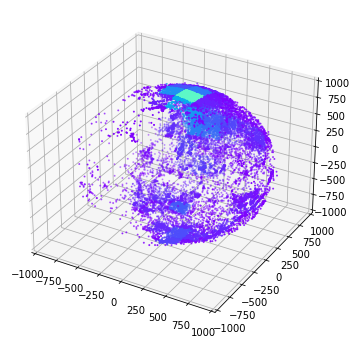

(6770, 6770)


<Figure size 432x288 with 0 Axes>

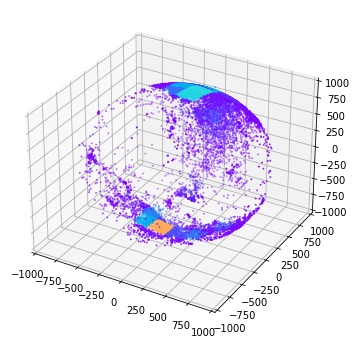

(6802, 6802)


<Figure size 432x288 with 0 Axes>

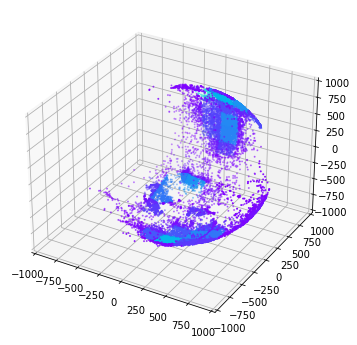

(6806, 6806)


<Figure size 432x288 with 0 Axes>

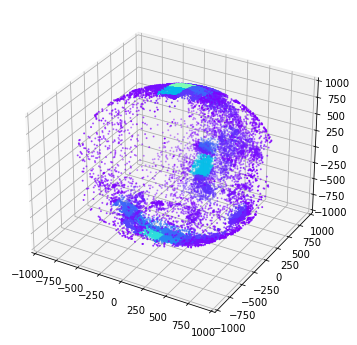

(6808, 6808)


<Figure size 432x288 with 0 Axes>

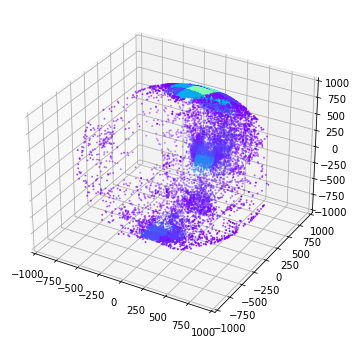

(6809, 6809)


<Figure size 432x288 with 0 Axes>

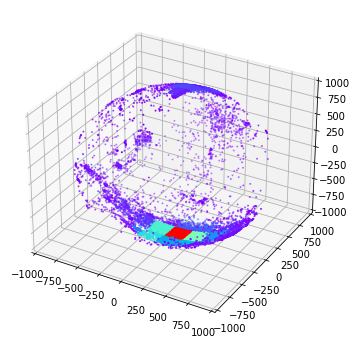

(6810, 6810)


<Figure size 432x288 with 0 Axes>

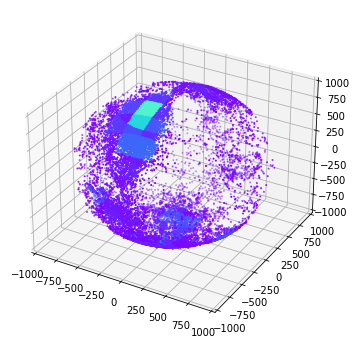

(6811, 6811)


<Figure size 432x288 with 0 Axes>

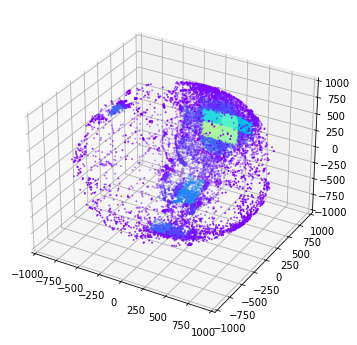

(6812, 6812)


<Figure size 432x288 with 0 Axes>

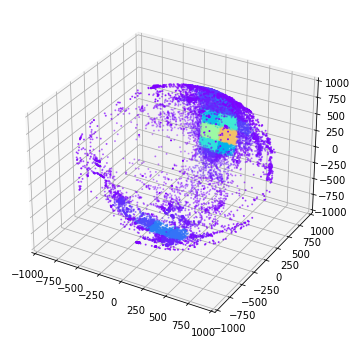

(6813, 6813)


<Figure size 432x288 with 0 Axes>

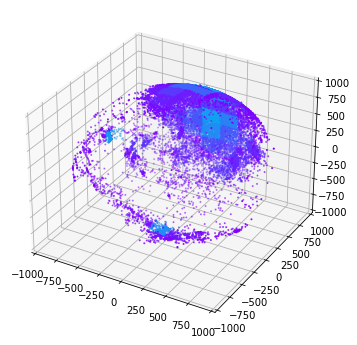

(6816, 6816)


<Figure size 432x288 with 0 Axes>

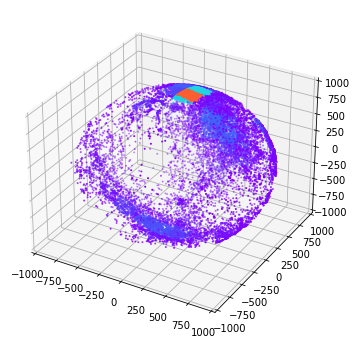

(6819, 6819)


<Figure size 432x288 with 0 Axes>

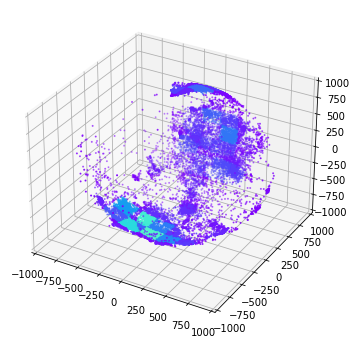

(6820, 6820)


<Figure size 432x288 with 0 Axes>

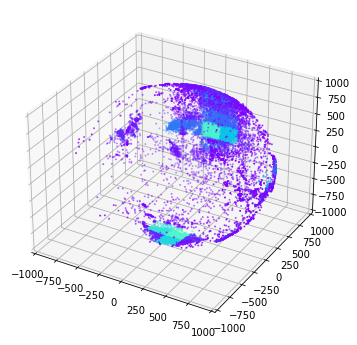

(6821, 6821)


<Figure size 432x288 with 0 Axes>

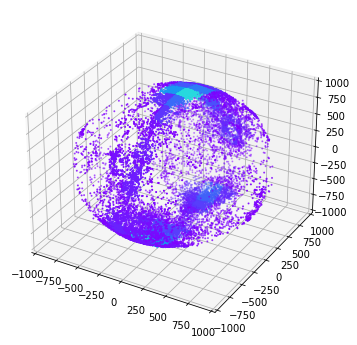

(6833, 6833)


<Figure size 432x288 with 0 Axes>

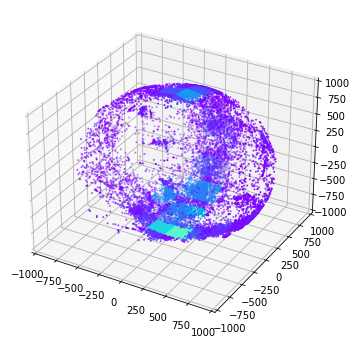

(6913, 6913)


<Figure size 432x288 with 0 Axes>

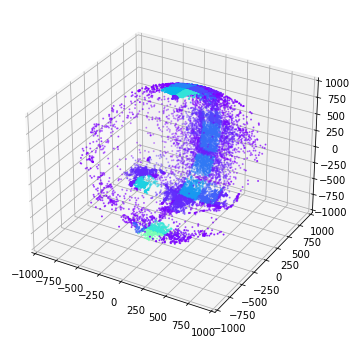

In [492]:
k=0
for i, filename in enumerate(sorted(set(tuple(label) for label in id6outr2))):
    print(filename)
    k=k+1
    #if k>2:
        #break
    if k>=1:
        indices = [j for j, label in enumerate(id6outr2) if tuple(label) == filename]
        #print(indices)
        plot_data = meanoutr62[indices]
        if len(plot_data)>=25200:
            hisin,edgein=np.histogramdd(plot_data[:25200], bins=edge6,density=True)
        else:
            hisin,edgein=np.histogramdd(plot_data, bins=edge6,density=True)
        hisind=hisin * np.diff(edgein[0])[0] * np.diff(edgein[1])[0] * np.diff(edgein[2])[0]
        edgein[0][10]=edgein[0][10]+0.00001
        edgein[0][0]=edgein[0][0]-0.00001
 
        edgein[1][10]=edgein[1][10]+0.00001
        edgein[1][0]=edgein[1][0]-0.00001

        edgein[2][10]=edgein[2][10]+0.00001
        edgein[2][0]=edgein[2][0]-0.00001
        if len(plot_data)>=25200:
            bin_indicesin = np.array([np.digitize(plot_data[:25200,ii], bins=edgein[ii]) for ii in range(3)])-1
        else:
            bin_indicesin = np.array([np.digitize(plot_data[:,ii], bins=edgein[ii]) for ii in range(3)])-1
        #print(np.max(bin_indicesin))

        fig=plt.figure(figsize=(6, 4))
        if len(plot_data)>=25200:
            fig=plt.figure(figsize=(6, 6))
            ax = fig.add_subplot(111, projection='3d')
            sc = ax.scatter(plot_data[:25200, 0], plot_data[:25200, 1], plot_data[:25200, 2], 
                            c=hisind[bin_indicesin[0][:25200], bin_indicesin[1][:25200], bin_indicesin[2][:25200]], cmap=cmap,
                            vmin=0,vmax=0.2,
                            s=1)
            #cbar = plt.colorbar(sc)
            #cbar.set_label('Histogram Value')
           
            ax.set_xlim(-1000,1000)
            ax.set_ylim(-1000,1000)
            ax.set_zlim(-1000,1000)
            plt.show()
            filesave=r'E:\DLR\motionhist\6m'+'\\'+str(filename)+'.jpg'
            #fig.savefig(filesave, bbox_inches='tight', pad_inches=0)

        else:
            fig=plt.figure(figsize=(6, 6))
            ax = fig.add_subplot(111, projection='3d')
            sc = ax.scatter(plot_data[:, 0], plot_data[:, 1], plot_data[:, 2], 
                            c=hisind[bin_indicesin[0], bin_indicesin[1], bin_indicesin[2]], cmap=cmap,
                            vmin=0,vmax=0.2,
                            s=1)
            #cbar = plt.colorbar(sc)
            ax.set_xlim(-1000,1000)
            ax.set_ylim(-1000,1000)
            ax.set_zlim(-1000,1000)
            plt.show()
            filesave=r'E:\DLR\motionhist\6m'+'\\'+str(filename)+'.jpg'
            #fig.savefig(filesave, bbox_inches='tight', pad_inches=0)
            #cbar.set_label('Histogram Value')

(9439, 9439)


<Figure size 432x288 with 0 Axes>

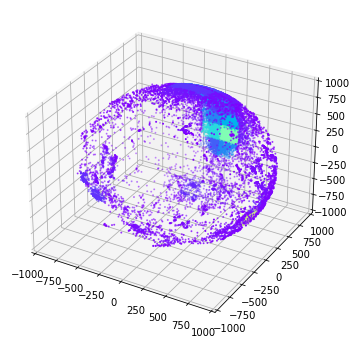

(9457, 9457)


<Figure size 432x288 with 0 Axes>

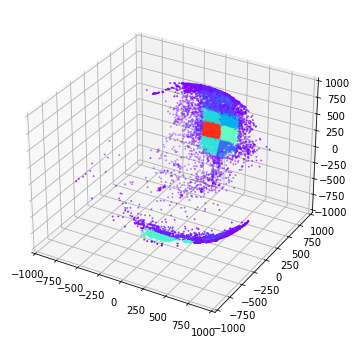

(9617, 9617)


<Figure size 432x288 with 0 Axes>

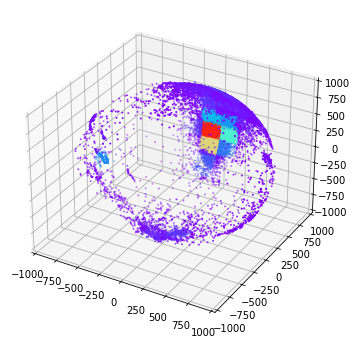

(9635, 9635)


<Figure size 432x288 with 0 Axes>

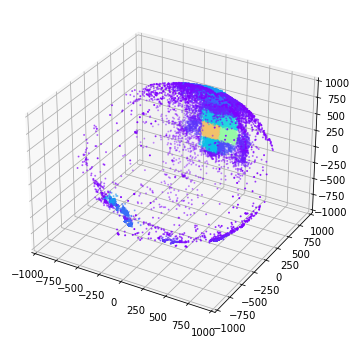

(9645, 9645)


<Figure size 432x288 with 0 Axes>

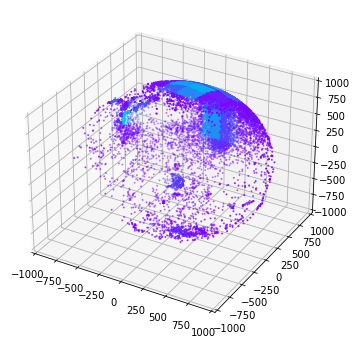

(9655, 9655)


<Figure size 432x288 with 0 Axes>

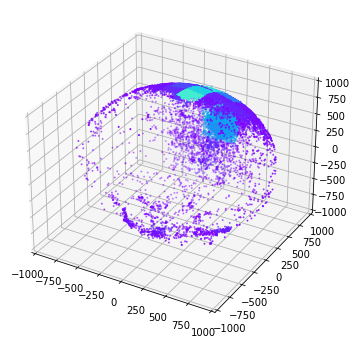

(9658, 9658)


<Figure size 432x288 with 0 Axes>

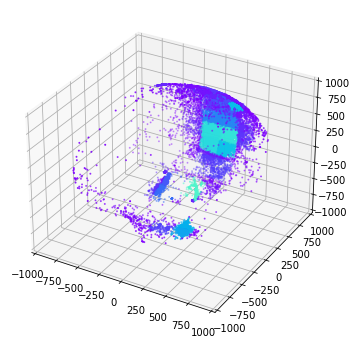

(9660, 9660)


<Figure size 432x288 with 0 Axes>

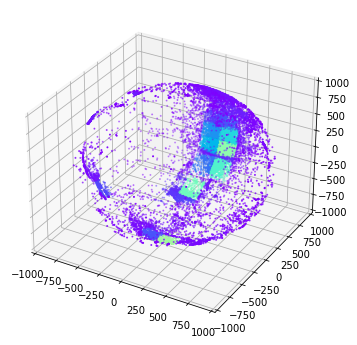

(9683, 9683)


<Figure size 432x288 with 0 Axes>

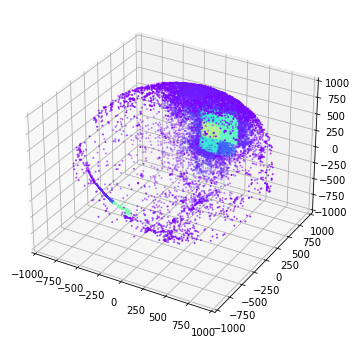

(9685, 9685)


<Figure size 432x288 with 0 Axes>

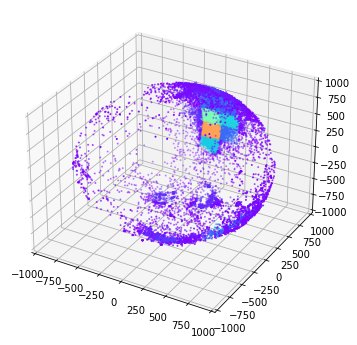

(9726, 9726)


<Figure size 432x288 with 0 Axes>

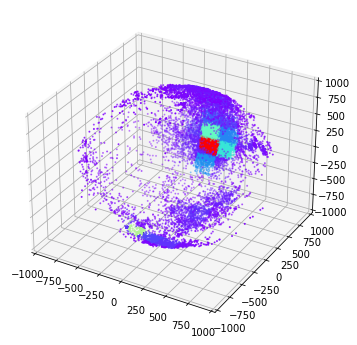

(9754, 9754)


<Figure size 432x288 with 0 Axes>

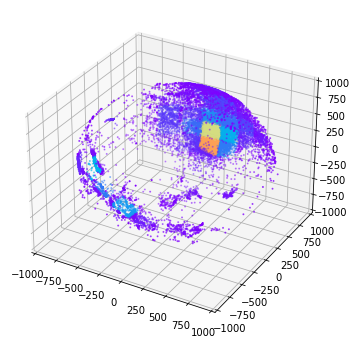

(9762, 9762)


<Figure size 432x288 with 0 Axes>

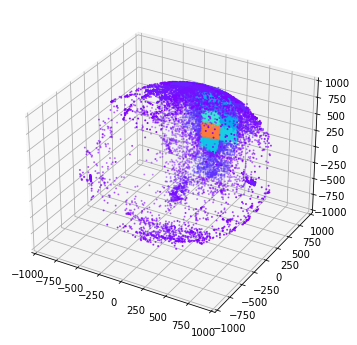

(9770, 9770)


<Figure size 432x288 with 0 Axes>

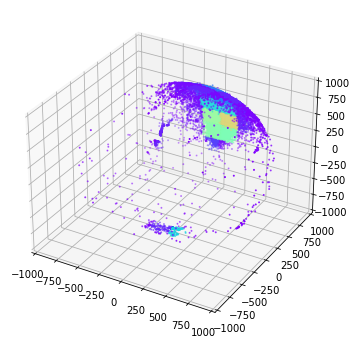

(9800, 9800)


<Figure size 432x288 with 0 Axes>

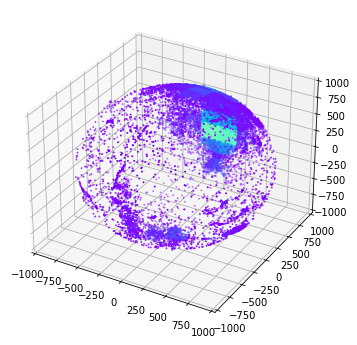

(9805, 9805)


<Figure size 432x288 with 0 Axes>

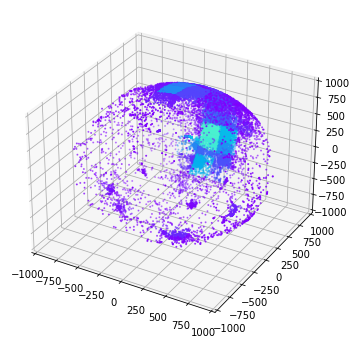

(9806, 9806)


<Figure size 432x288 with 0 Axes>

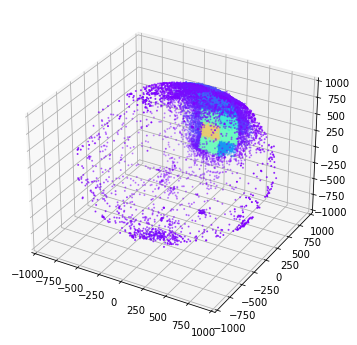

(9808, 9808)


<Figure size 432x288 with 0 Axes>

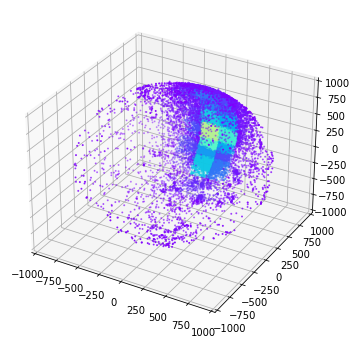

(9809, 9809)


<Figure size 432x288 with 0 Axes>

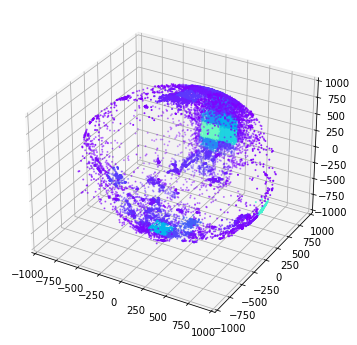

(9810, 9810)


<Figure size 432x288 with 0 Axes>

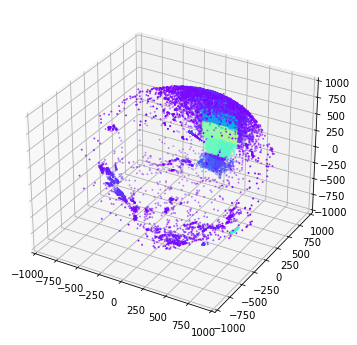

(9811, 9811)


<Figure size 432x288 with 0 Axes>

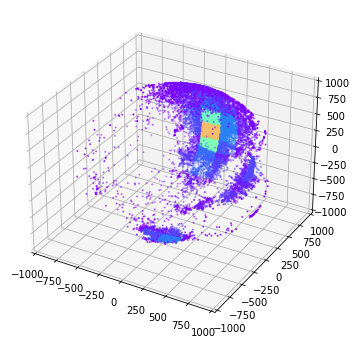

(9812, 9812)


<Figure size 432x288 with 0 Axes>

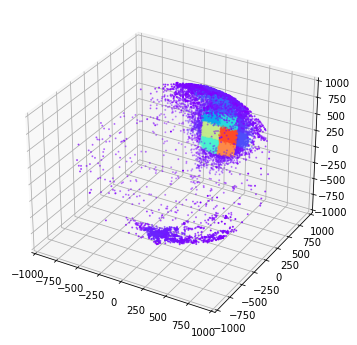

(9814, 9814)


<Figure size 432x288 with 0 Axes>

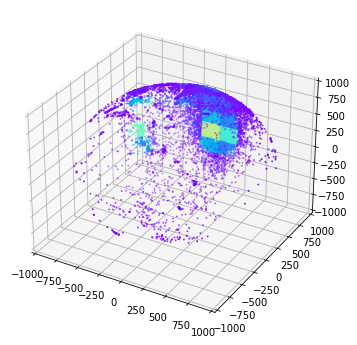

(9815, 9815)


<Figure size 432x288 with 0 Axes>

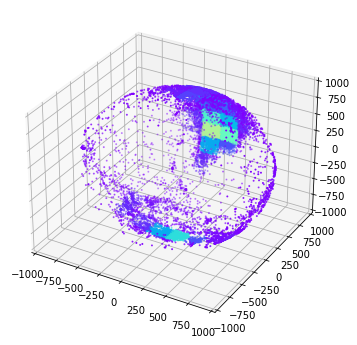

(9816, 9816)


<Figure size 432x288 with 0 Axes>

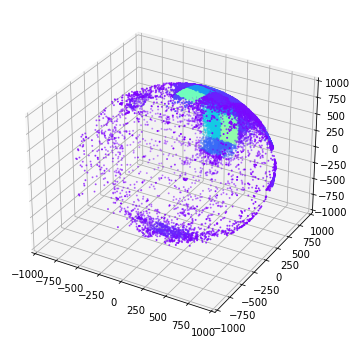

(9820, 9820)


<Figure size 432x288 with 0 Axes>

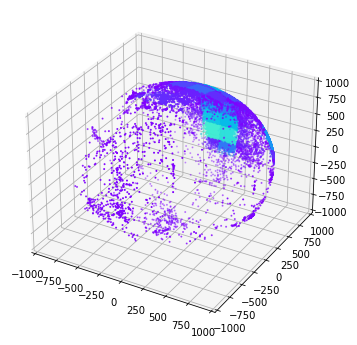

(9822, 9822)


<Figure size 432x288 with 0 Axes>

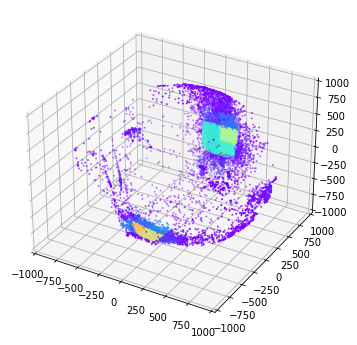

(9833, 9833)


<Figure size 432x288 with 0 Axes>

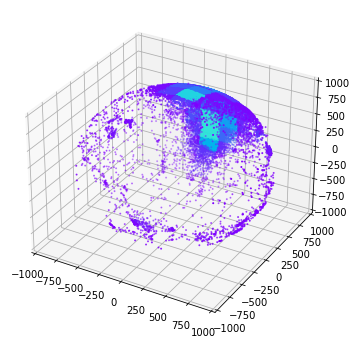

(9913, 9913)


<Figure size 432x288 with 0 Axes>

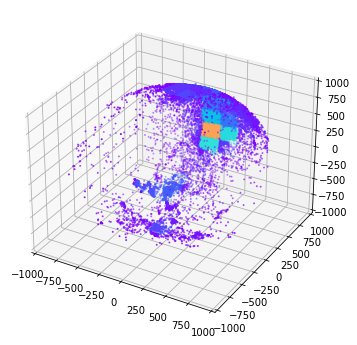

In [493]:
k=0
for i, filename in enumerate(sorted(set(tuple(label) for label in id9outr2))):
    print(filename)
    k=k+1
    #if k>2:
        #break
    if k>=1:
        indices = [j for j, label in enumerate(id9outr2) if tuple(label) == filename]
        #print(indices)
        plot_data = meanoutr92[indices]
        if len(plot_data)>=25200:
            hisin,edgein=np.histogramdd(plot_data[:25200], bins=edge9,density=True)
        else:
            hisin,edgein=np.histogramdd(plot_data, bins=edge9,density=True)
        hisind=hisin * np.diff(edgein[0])[0] * np.diff(edgein[1])[0] * np.diff(edgein[2])[0]
        edgein[0][10]=edgein[0][10]+0.00001
        edgein[0][0]=edgein[0][0]-0.00001
 
        edgein[1][10]=edgein[1][10]+0.00001
        edgein[1][0]=edgein[1][0]-0.00001

        edgein[2][10]=edgein[2][10]+0.00001
        edgein[2][0]=edgein[2][0]-0.00001
        if len(plot_data)>=25200:
            bin_indicesin = np.array([np.digitize(plot_data[:25200,ii], bins=edgein[ii]) for ii in range(3)])-1
        else:
            bin_indicesin = np.array([np.digitize(plot_data[:,ii], bins=edgein[ii]) for ii in range(3)])-1
        #print(np.max(bin_indicesin))

        fig=plt.figure(figsize=(6, 4))
        if len(plot_data)>=25200:
            fig=plt.figure(figsize=(6, 6))
            ax = fig.add_subplot(111, projection='3d')
            sc = ax.scatter(plot_data[:25200, 0], plot_data[:25200, 1], plot_data[:25200, 2], 
                            c=hisind[bin_indicesin[0][:25200], bin_indicesin[1][:25200], bin_indicesin[2][:25200]], cmap=cmap,
                            vmin=0,vmax=0.2,
                            s=1)
            #cbar = plt.colorbar(sc)
            ax.set_xlim(-1000,1000)
            ax.set_ylim(-1000,1000)
            ax.set_zlim(-1000,1000)
            #cbar.set_label('Histogram Value')
            plt.show()
            filesave=r'E:\DLR\motionhist\9m'+'\\'+str(filename)+'.jpg'
            fig.savefig(filesave, bbox_inches='tight', pad_inches=0)

        else:
            fig=plt.figure(figsize=(6, 6))
            ax = fig.add_subplot(111, projection='3d')
            sc = ax.scatter(plot_data[:, 0], plot_data[:, 1], plot_data[:, 2], 
                            c=hisind[bin_indicesin[0], bin_indicesin[1], bin_indicesin[2]], cmap=cmap,vmin=0,vmax=0.2,
                            s=1)
            #cbar = plt.colorbar(sc)
            ax.set_xlim(-1000,1000)
            ax.set_ylim(-1000,1000)
            ax.set_zlim(-1000,1000)
            plt.show()
            filesave=r'E:\DLR\motionhist\9m'+'\\'+str(filename)+'.jpg'
            fig.savefig(filesave, bbox_inches='tight', pad_inches=0)
            #cbar.set_label('Histogram Value')

(12439, 12439)


<Figure size 432x288 with 0 Axes>

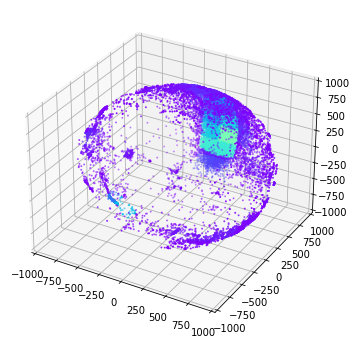

(12457, 12457)


<Figure size 432x288 with 0 Axes>

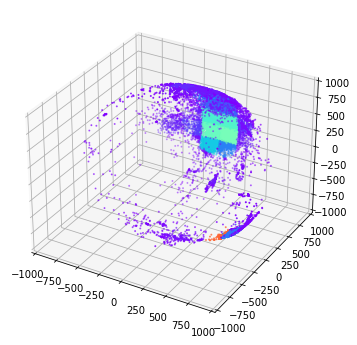

(12507, 12507)


<Figure size 432x288 with 0 Axes>

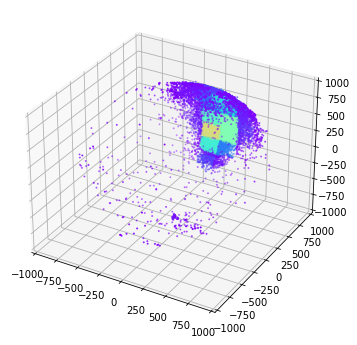

(12617, 12617)


<Figure size 432x288 with 0 Axes>

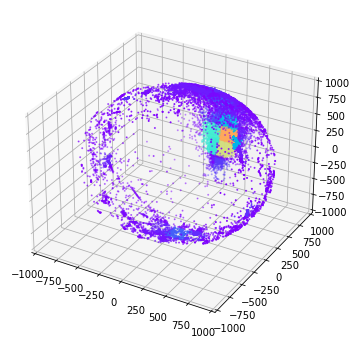

(12655, 12655)


<Figure size 432x288 with 0 Axes>

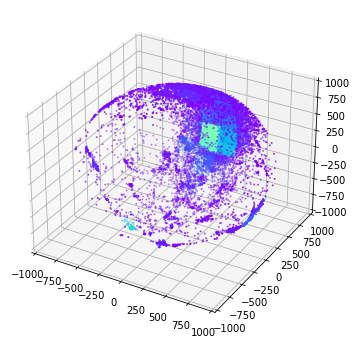

(12683, 12683)


<Figure size 432x288 with 0 Axes>

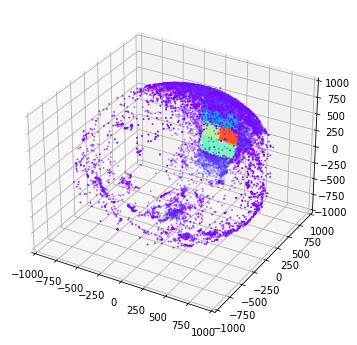

(12685, 12685)


<Figure size 432x288 with 0 Axes>

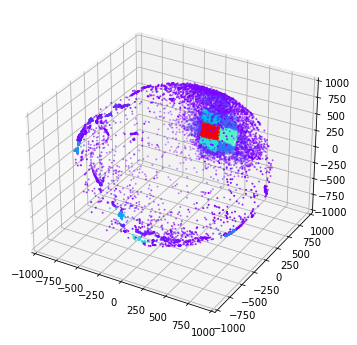

(12726, 12726)


<Figure size 432x288 with 0 Axes>

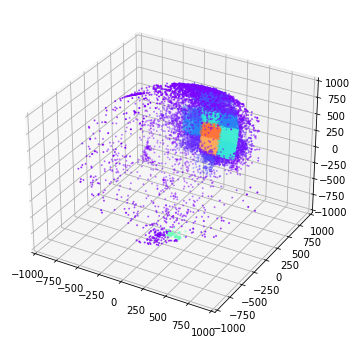

(12754, 12754)


<Figure size 432x288 with 0 Axes>

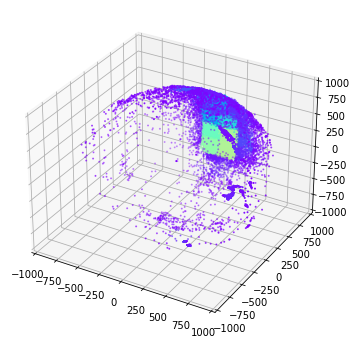

(12762, 12762)


<Figure size 432x288 with 0 Axes>

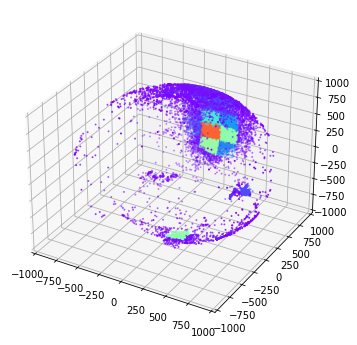

(12805, 12805)


<Figure size 432x288 with 0 Axes>

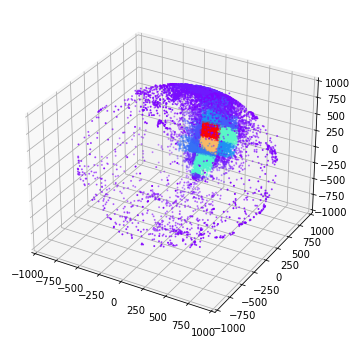

(12806, 12806)


<Figure size 432x288 with 0 Axes>

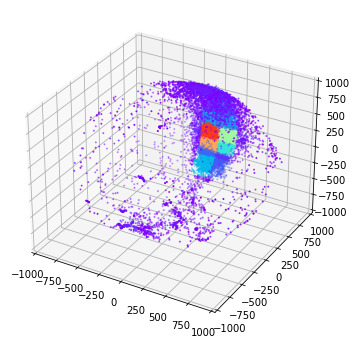

(12812, 12812)


<Figure size 432x288 with 0 Axes>

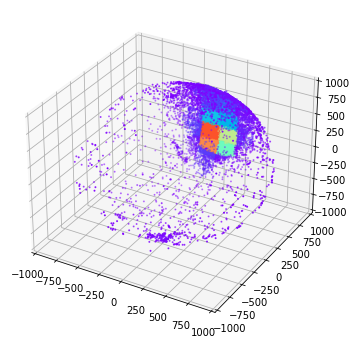

(12813, 12813)


<Figure size 432x288 with 0 Axes>

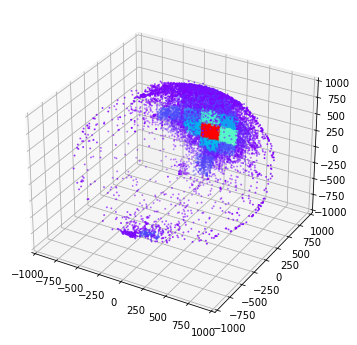

(12814, 12814)


<Figure size 432x288 with 0 Axes>

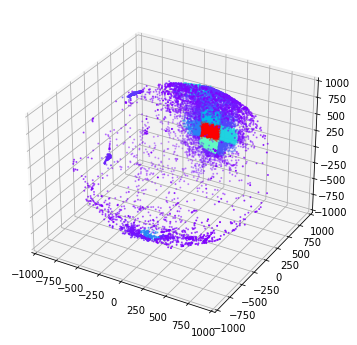

(12815, 12815)


<Figure size 432x288 with 0 Axes>

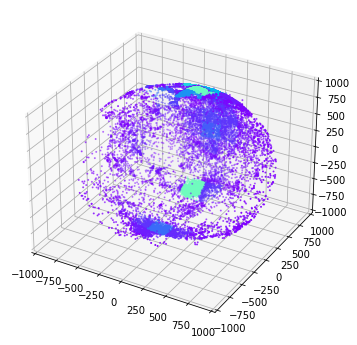

(12816, 12816)


<Figure size 432x288 with 0 Axes>

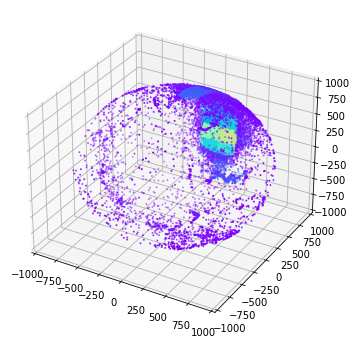

(12819, 12819)


<Figure size 432x288 with 0 Axes>

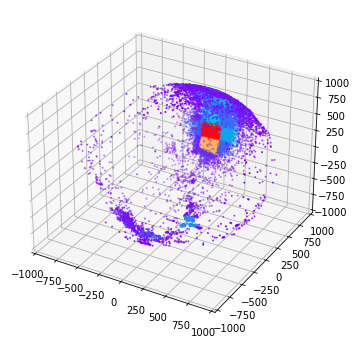

(12820, 12820)


<Figure size 432x288 with 0 Axes>

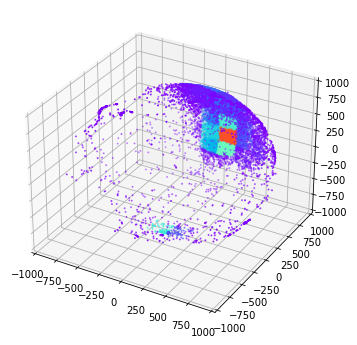

(12913, 12913)


<Figure size 432x288 with 0 Axes>

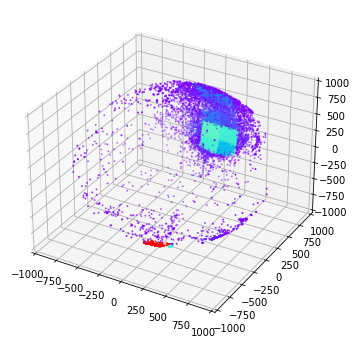

In [494]:
k=0
for i, filename in enumerate(sorted(set(tuple(label) for label in id12outr2))):
    print(filename)
    k=k+1
    #if k>2:
        #break
    if k>=1:
        indices = [j for j, label in enumerate(id12outr2) if tuple(label) == filename]
        #print(indices)
        plot_data = meanoutr122[indices]
        if len(plot_data)>=25200:
            hisin,edgein=np.histogramdd(plot_data[:25200], bins=edge12,density=True)
        else:
            hisin,edgein=np.histogramdd(plot_data, bins=edge12,density=True)
        hisind=hisin * np.diff(edgein[0])[0] * np.diff(edgein[1])[0] * np.diff(edgein[2])[0]
        edgein[0][10]=edgein[0][10]+0.00001
        edgein[0][0]=edgein[0][0]-0.00001
 
        edgein[1][10]=edgein[1][10]+0.00001
        edgein[1][0]=edgein[1][0]-0.00001

        edgein[2][10]=edgein[2][10]+0.00001
        edgein[2][0]=edgein[2][0]-0.00001
        if len(plot_data)>=25200:
            bin_indicesin = np.array([np.digitize(plot_data[:25200,ii], bins=edgein[ii]) for ii in range(3)])-1
        else:
            bin_indicesin = np.array([np.digitize(plot_data[:,ii], bins=edgein[ii]) for ii in range(3)])-1
        #print(np.max(bin_indicesin))

        fig=plt.figure(figsize=(6, 4))
        if len(plot_data)>=25200:
            fig=plt.figure(figsize=(6, 6))
            ax = fig.add_subplot(111, projection='3d')
            sc = ax.scatter(plot_data[:25200, 0], plot_data[:25200, 1], plot_data[:25200, 2], 
                            c=hisind[bin_indicesin[0][:25200], bin_indicesin[1][:25200], bin_indicesin[2][:25200]], cmap=cmap,
                            vmin=0,vmax=0.2,
                            s=1)
            #cbar = plt.colorbar(sc)
            ax.set_xlim(-1000,1000)
            ax.set_ylim(-1000,1000)
            ax.set_zlim(-1000,1000)
            #cbar.set_label('Histogram Value')
            plt.show()
            filesave=r'E:\DLR\motionhist\12m'+'\\'+str(filename)+'.jpg'
            fig.savefig(filesave, bbox_inches='tight', pad_inches=0)

        else:
            fig=plt.figure(figsize=(6, 6))
            ax = fig.add_subplot(111, projection='3d')
            sc = ax.scatter(plot_data[:, 0], plot_data[:, 1], plot_data[:, 2], 
                            c=hisind[bin_indicesin[0], bin_indicesin[1], bin_indicesin[2]], cmap=cmap,vmin=0,vmax=0.2,
                            s=1)
            #cbar = plt.colorbar(sc)
            ax.set_xlim(-1000,1000)
            ax.set_ylim(-1000,1000)
            ax.set_zlim(-1000,1000)
            plt.show()
            filesave=r'E:\DLR\motionhist\12m'+'\\'+str(filename)+'.jpg'
            fig.savefig(filesave, bbox_inches='tight', pad_inches=0)
            #cbar.set_label('Histogram Value')

In [452]:
def plotall(pathin,datain,namein):
    fig=plt.figure(figsize=(30,16))
    num_rows = len(datain)//7+(len(datain)%7>0)
    for i,file_name in enumerate(datain):
        full_path=pathin+'/'+file_name
        plt.subplot(num_rows,7,i+1)
        
        img=plt.imread(full_path)
        plt.imshow(img,cmap=plt.cm.gray)
        #plt.xticks([])
        #plt.yticks([])
        plt.axis('off')
    plt.subplots_adjust(wspace=0.1)
    
    plt.tight_layout()
    plt.show()
    fig.savefig(namein,bbox_inches='tight', pad_inches=0,dpi=300)

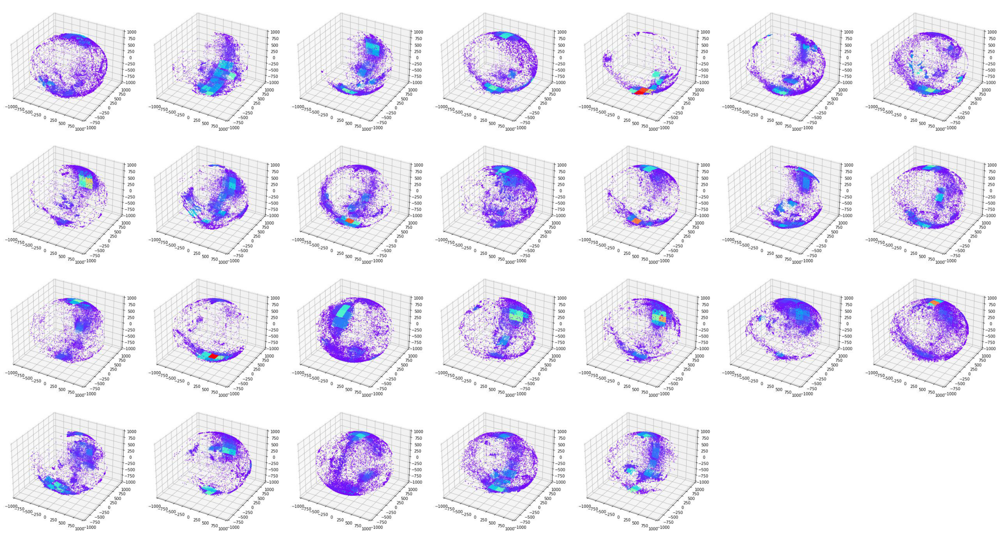

In [498]:
path_6mspex=r'E:\DLR\motionhist\6m'
images6mx=os.listdir(path_6mspex)
images6mx.sort()
pathsave=r'E:\DLR\motionhist\all6m'
path6mxin=pathsave
plotall(path_6mspex,images6mx,path6mxin)